# 07 · Work mode: remote, hybrid, on-site

How common are remote and hybrid IT jobs, and is the share changing?

**Method.** Only some postings state a work mode, and which ones do depends on the source, so every share is **of postings that state a mode**, and the coverage comes first. The field is usable from 2025 only (about 3 % of 2024 postings state one), so the window is January 2025 to October 2026. Modes are normalised to remote, hybrid and on-site; field work and offshore are left out.

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/; the modules are one level up.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import display

import analysis as a
import work_mode as w

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. Coverage: who states a mode

Per source, from January 2025: how many postings, what share state a mode, and the remote-or-hybrid share among those that do.

In [2]:
coverage = w.coverage_by_source(df)
a.save_table(coverage, "07-work-mode-coverage")
coverage

,source,postings,pct_state_mode,remote_or_hybrid_of_stated
0,LinkedIn,32913,18.0,73.5
1,Jora,13745,1.6,71.0
2,CareerBuilder,5963,19.1,6.7
3,CareerViet,5281,40.6,0.7
4,CareerJet,3633,15.2,82.8
5,Monster Asia,3625,12.5,63.4
6,SmartRecruiters,1610,75.3,15.3


## 2. Over time

Quarterly share of each mode among postings that state one, for all sources and the three sources with the most statements.

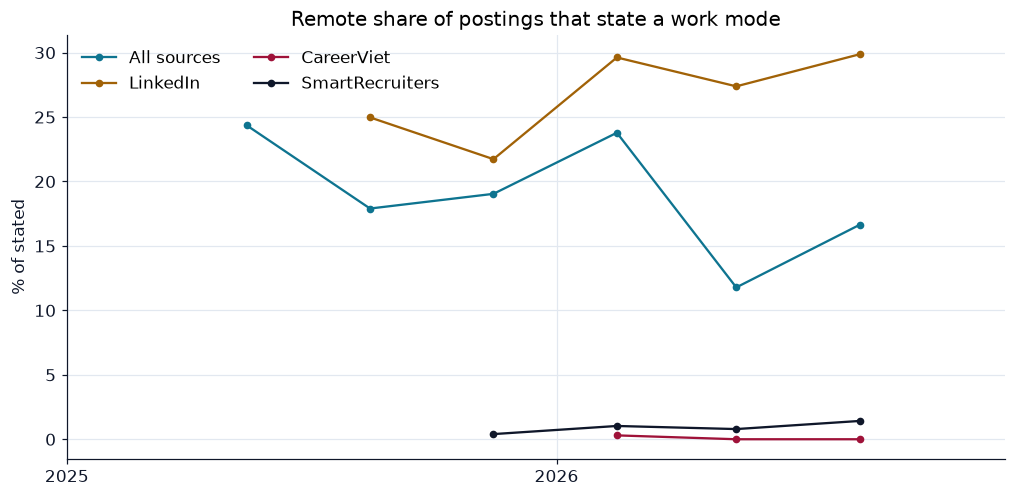

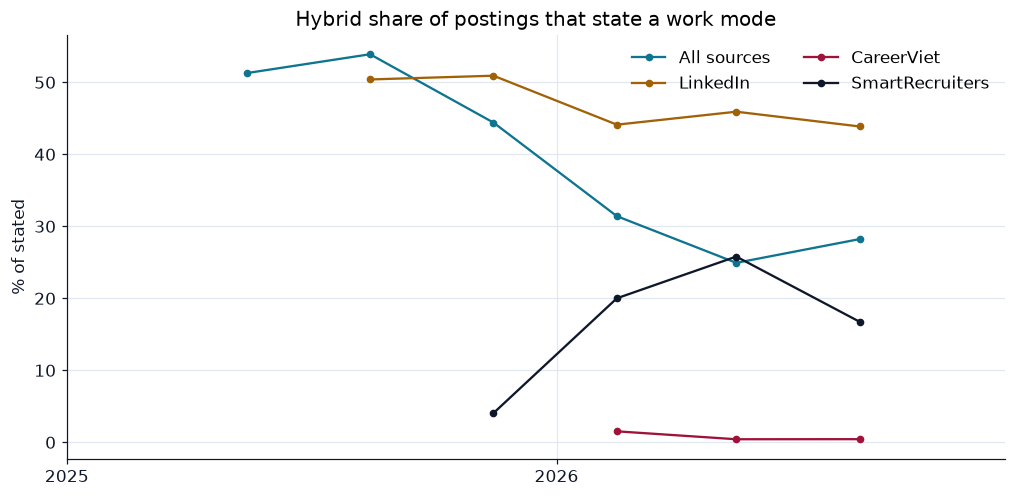

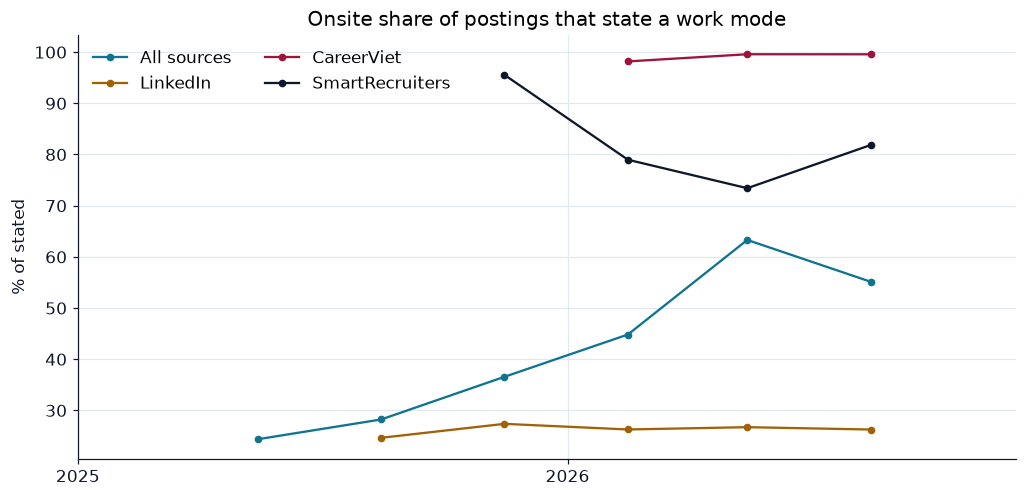

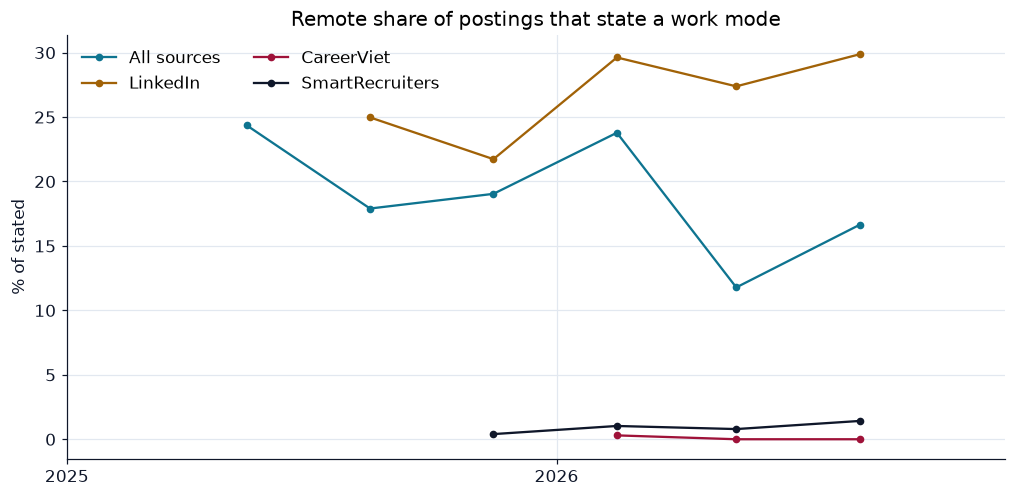

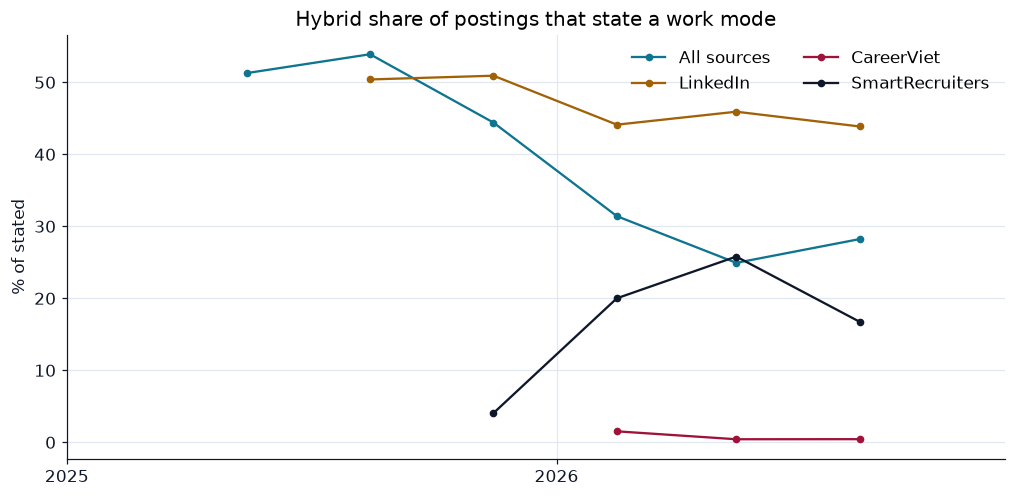

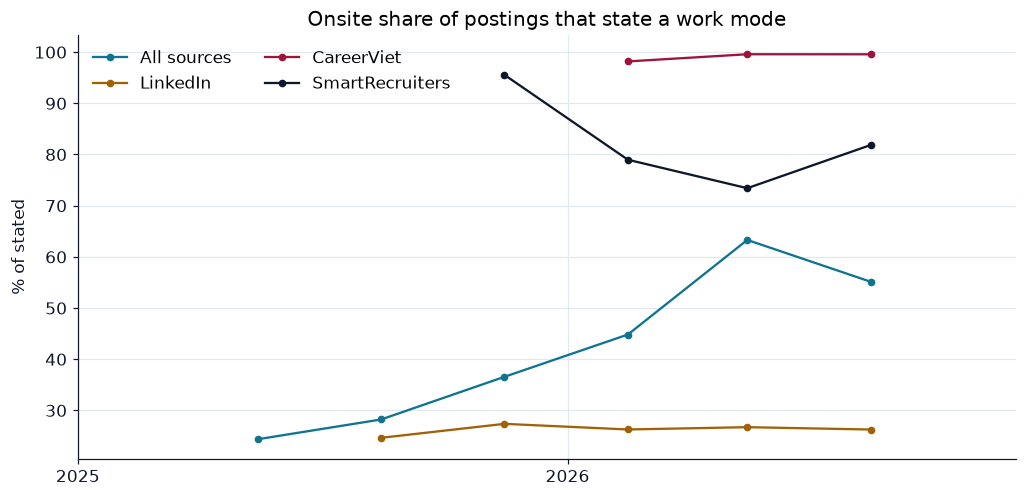

In [3]:
for mode in w.MODES:
    series = w.mode_series(df, mode)
    fig = a.trend_lines(
        series,
        f"{mode.capitalize()} share of postings that state a work mode",
        "% of stated",
        start=2025,
    )
    a.save_chart(fig, f"07-{mode}-share")
    rows = [f.assign(scope=n) for n, f in series.items()]
    a.save_table(pd.concat(rows).drop(columns="period_date"), f"07-{mode}-share")
    display(fig)

## 3. By role

Remote, hybrid and on-site shares among postings that state a mode, per role (2025 on, roles with at least 100 stated).

In [4]:
by_role = w.by_group(df, "role")
a.save_table(by_role, "07-mode-by-role")
by_role

,group,stated,remote,hybrid,onsite
0,game,137,36.5,46.7,16.8
1,ai_ml,1185,31.1,33.2,35.6
2,frontend,457,26.0,45.7,28.2
3,fullstack,918,24.7,45.3,30.0
4,backend,1209,20.4,49.5,30.1
5,mobile,260,18.8,43.8,37.3
6,software_other,1447,18.4,34.8,46.9
7,devops_cloud,1010,17.5,41.9,40.6
8,data,1173,17.1,33.4,49.4
9,security,392,16.3,27.3,56.4


## 4. By city

The same split by city group.

In [5]:
by_city = w.by_group(df, "city_group")
a.save_table(by_city, "07-mode-by-city")
by_city

,group,stated,remote,hybrid,onsite
0,Unknown,161,30.4,31.7,37.9
1,Other,3436,24.9,26.1,48.9
2,Hà Nội,2955,16.5,25.2,58.2
3,Đà Nẵng,365,16.2,51.0,32.9
4,Hồ Chí Minh,5855,11.9,40.0,48.1


## Findings

1. **Few postings state a work mode, and the boards disagree on what it means.** From 2025, the share stating a mode is 18 % on LinkedIn, 19 % on CareerBuilder, 41 % on CareerViet, 75 % on SmartRecruiters and 1.6 % on Jora. Among the postings that do state one, remote-or-hybrid is 74 % on LinkedIn, 83 % on CareerJet and 63 % on Monster Asia, but 6.7 % on CareerBuilder, 15 % on SmartRecruiters and 0.7 % on CareerViet. Those gaps are far too wide to be the market, so an all-source share is mostly a mix of boards.
2. **The all-source on-site share rises, but that is the source mix.** All sources: on-site 28 % (2025-Q3) → 55 % (2026-Q3), remote 18 % → 17 % with a dip to 12 %, hybrid 54 % → 28 %. The change coincides with CareerViet (99 % on-site) arriving in 2026. Inside LinkedIn, the one large source with statements throughout: remote 25 % → 30 %, hybrid 50 % → 44 %, on-site 25 % → 26 %, roughly steady. This data does not show remote or hybrid work shrinking.
3. **By role** (postings that state a mode, 2025 on): remote is highest for game (36.5 %), AI / ML (31.1 %), frontend (26.0 %), full-stack (24.7 %) and backend (20.4 %), and lowest for embedded (5.2 %), technicians (4.2 %) and IT support (7.5 %). Role mix differs by source, so this is indicative.
4. **By city:** hybrid is commonest in Đà Nẵng (51 %) and Hồ Chí Minh (40 %), against 25 % in Hà Nội; remote is 16.5 % in Hà Nội, 16.2 % in Đà Nẵng and 11.9 % in Hồ Chí Minh.

**What this notebook cannot say:** whether remote work grew or shrank. Inside LinkedIn it is steady; elsewhere there is not enough stated data to tell.
